# How are period and amplitude related?

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
from scipy import stats
from stats_toolkit import pearson_r

rr = pd.read_csv("../data/raw/gaia_dr3_rrlyrae_pilot_raw.csv")
rr["period"] = rr["pf"].fillna(rr["p1_o"])
rr["period_type"] = np.where(rr["pf"].notna(), "fundamental", "overtone")
rr["log_period"] = np.log10(rr["period"])
print(rr.shape)

(2000, 13)


In [2]:
fund = rr[rr["period_type"] == "fundamental"].dropna(subset=["log_period", "peak_to_peak_g"])

mine = pearson_r(fund["log_period"], fund["peak_to_peak_g"])
theirs = stats.pearsonr(fund["log_period"], fund["peak_to_peak_g"])[0]

print("n =", len(fund))
print("mine  :", mine)
print("scipy :", theirs)
print("difference:", abs(mine - theirs))

n = 1262
mine  : -0.3820991923788068
scipy : -0.38209919237880685
difference: 5.551115123125783e-17


In [3]:
from stats_toolkit import correlation_summary

res = correlation_summary(fund["log_period"], fund["peak_to_peak_g"])
for k, v in res.items():
    print(k, ":", v)

# check the interval against scipy
sp = stats.pearsonr(fund["log_period"], fund["peak_to_peak_g"])
print("scipy 95% CI:", sp.confidence_interval())

n : 1262
r : -0.3820991923788068
r2 : 0.1459997928165364
se : 0.02403965875881792
pe : 0.016214749832822686
ci95 : (np.float64(-0.42825196419373496), np.float64(-0.33395821716533786))
scipy 95% CI: ConfidenceInterval(low=np.float64(-0.42825113532491954), high=np.float64(-0.3339591189849056))


In [4]:
import pandas as pd

rr2 = rr.dropna(subset=["log_period", "peak_to_peak_g"])
groups = {
    "pooled": rr2,
    "fundamental": rr2[rr2["period_type"] == "fundamental"],
    "overtone": rr2[rr2["period_type"] == "overtone"],
}

rows = []
for name, d in groups.items():
    s = correlation_summary(d["log_period"], d["peak_to_peak_g"])
    rows.append({"group": name, "n": s["n"], "r": s["r"], "r2": s["r2"],
                 "ci_low": s["ci95"][0], "ci_high": s["ci95"][1]})

pd.DataFrame(rows).round(3)

,group,n,r,r2,ci_low,ci_high
0,pooled,2000,0.403,0.163,0.366,0.439
1,fundamental,1262,-0.382,0.146,-0.428,-0.334
2,overtone,738,0.218,0.047,0.148,0.285


pooled: slope 0.787 (scipy 0.787), intercept 0.820 (scipy 0.820)
fundamental: slope -1.526 (scipy -1.526), intercept 0.278 (scipy 0.278)
overtone: slope 0.347 (scipy 0.347), intercept 0.517 (scipy 0.517)


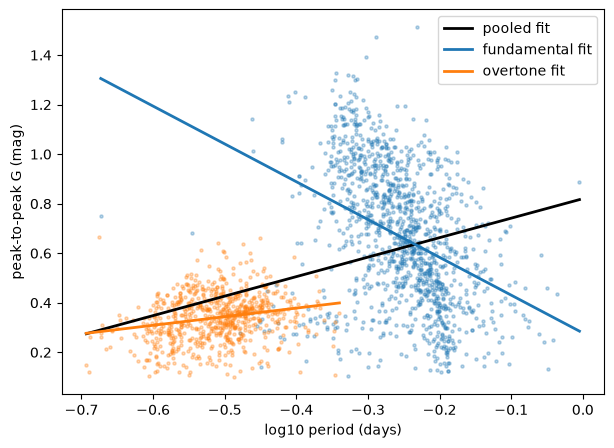

In [5]:
import matplotlib.pyplot as plt
from stats_toolkit import linear_fit

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"fundamental": "tab:blue", "overtone": "tab:orange", "pooled": "black"}

for k in ["fundamental", "overtone"]:
    d = groups[k]
    ax.scatter(d["log_period"], d["peak_to_peak_g"], s=5, alpha=0.3, color=colors[k])

for name, d in groups.items():
    a, b = linear_fit(d["log_period"], d["peak_to_peak_g"])
    chk = stats.linregress(d["log_period"], d["peak_to_peak_g"])
    print(f"{name}: slope {b:.3f} (scipy {chk.slope:.3f}), intercept {a:.3f} (scipy {chk.intercept:.3f})")
    xs = np.linspace(d["log_period"].min(), d["log_period"].max(), 50)
    ax.plot(xs, a + b * xs, color=colors[name], lw=2, label=f"{name} fit")

ax.set_xlabel("log10 period (days)")
ax.set_ylabel("peak-to-peak G (mag)")
ax.legend()
plt.show()

In [6]:
from stats_toolkit import two_regression_lines

d = groups["fundamental"]
res2 = two_regression_lines(d["log_period"], d["peak_to_peak_g"])
for k, v in res2.items():
    print(k, ":", v)

print("pearson_r :", pearson_r(d["log_period"], d["peak_to_peak_g"]))

b_yx : -1.5262661614412965
b_xy : -0.09565814698968668
r2_from_slopes : 0.14599979281653638
r_from_slopes : -0.38209919237880674
pearson_r : -0.3820991923788068


In [7]:
from stats_toolkit import spearman_rho

for name, d in groups.items():
    x, y = d["log_period"], d["peak_to_peak_g"]
    print(name,
          "| pearson", round(pearson_r(x, y), 4),
          "| spearman mine", round(spearman_rho(x, y), 4),
          "| scipy", round(stats.spearmanr(x, y)[0], 4))

pooled | pearson 0.4031 | spearman mine 0.3665 | scipy 0.3665
fundamental | pearson -0.3821 | spearman mine -0.4424 | scipy -0.4424
overtone | pearson 0.2177 | spearman mine 0.2313 | scipy 0.2313


In [8]:
from stats_toolkit import polynomial_fit, poly_predict, r_squared, linear_fit

d = groups["fundamental"]
x = d["log_period"].to_numpy()          # log10 period
y = d["peak_to_peak_g"].to_numpy()      # amplitude (mag)
P = 10 ** x                             # period in days

rows = []

# polynomials in log10 period, checked against numpy
for deg, label in [(1, "line"), (2, "parabola"), (3, "cubic")]:
    c = polynomial_fit(x, y, deg)
    ok = np.allclose(c, np.polyfit(x, y, deg)[::-1])
    rows.append({"model": label, "R2": r_squared(y, poly_predict(c, x)), "matches numpy": ok})

# power law  y = A * P^B  (straight line in log-log)
a, b = linear_fit(x, np.log10(y))
rows.append({"model": "power law", "R2": r_squared(y, 10 ** (a + b * x)), "matches numpy": "n/a"})

# exponential  y = A * exp(k * P)  (straight line in ln y vs P)
a2, k = linear_fit(P, np.log(y))
rows.append({"model": "exponential", "R2": r_squared(y, np.exp(a2 + k * P)), "matches numpy": "n/a"})

pd.DataFrame(rows).round(4)

,model,R2,matches numpy
0,line,0.1460,True
1,parabola,0.1767,True
2,cubic,0.1845,True
3,power law,0.0754,n/a
4,exponential,0.1055,n/a


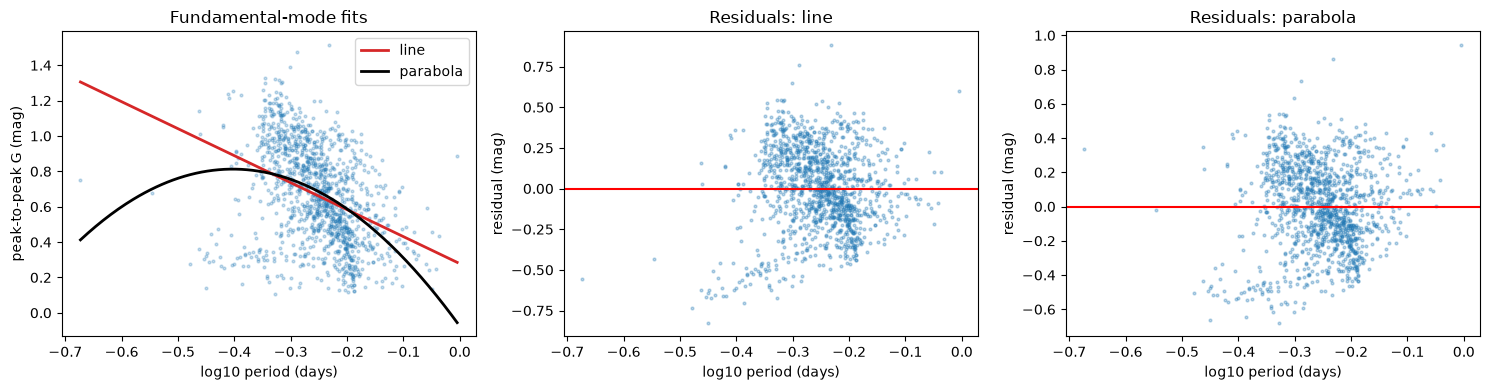

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
xs = np.linspace(x.min(), x.max(), 200)

ax[0].scatter(x, y, s=4, alpha=0.25)
for deg, label, col in [(1, "line", "tab:red"), (2, "parabola", "black")]:
    c = polynomial_fit(x, y, deg)
    ax[0].plot(xs, poly_predict(c, xs), color=col, lw=2, label=label)
ax[0].set_xlabel("log10 period (days)")
ax[0].set_ylabel("peak-to-peak G (mag)")
ax[0].set_title("Fundamental-mode fits")
ax[0].legend()

for a, deg, title in [(ax[1], 1, "Residuals: line"), (ax[2], 2, "Residuals: parabola")]:
    c = polynomial_fit(x, y, deg)
    a.scatter(x, y - poly_predict(c, x), s=4, alpha=0.3)
    a.axhline(0, color="red")
    a.set_xlabel("log10 period (days)")
    a.set_ylabel("residual (mag)")
    a.set_title(title)

plt.tight_layout()
plt.show()

In [10]:
x = d["log_period"].to_numpy()
y = d["peak_to_peak_g"].to_numpy()

print("original                          :", round(pearson_r(x, y), 6))
print("x shifted by +5                   :", round(pearson_r(x + 5, y), 6))
print("y scaled by 1000 (mag -> mmag)    :", round(pearson_r(x, y * 1000), 6))
print("both: 3x + 2 and 0.5y - 7         :", round(pearson_r(3 * x + 2, 0.5 * y - 7), 6))
print("x multiplied by -1                :", round(pearson_r(-x, y), 6))
print("symmetry, r(y, x)                 :", round(pearson_r(y, x), 6))
print("bounds check, r(x, x)             :", round(pearson_r(x, x), 6))

original                          : -0.382099
x shifted by +5                   : -0.382099
y scaled by 1000 (mag -> mmag)    : -0.382099
both: 3x + 2 and 0.5y - 7         : -0.382099
x multiplied by -1                : 0.382099
symmetry, r(y, x)                 : -0.382099
bounds check, r(x, x)             : 1.0


In [11]:
r2d = rr2.copy()
r2d["period_band"] = pd.cut(r2d["log_period"], bins=5)
r2d["amplitude_band"] = pd.cut(r2d["peak_to_peak_g"], bins=5)

# joint frequency table, with marginal totals
joint = pd.crosstab(r2d["period_band"], r2d["amplitude_band"], margins=True, margins_name="total")
print(joint)

# joint relative frequencies (each cell / grand total)
print((pd.crosstab(r2d["period_band"], r2d["amplitude_band"], normalize="all")).round(3))

# conditional distribution of amplitude within each period band (each row sums to 1)
print((pd.crosstab(r2d["period_band"], r2d["amplitude_band"], normalize="index")).round(3))

amplitude_band      (0.0988, 0.383]  (0.383, 0.665]  (0.665, 0.948]  \
period_band                                                           
(-0.694, -0.556]                148              33               2   
(-0.556, -0.418]                341             186               1   
(-0.418, -0.28]                  78              68             145   
(-0.28, -0.142]                 141             331             240   
(-0.142, -0.00471]               26              22               8   
total                           734             640             396   

amplitude_band      (0.948, 1.231]  (1.231, 1.513]  total  
period_band                                                
(-0.694, -0.556]                 0               0    183  
(-0.556, -0.418]                 4               0    532  
(-0.418, -0.28]                141              15    447  
(-0.28, -0.142]                 69               1    782  
(-0.142, -0.00471]               0               0     56  
total      

In [12]:
from stats_toolkit import kendall_tau_b

for name, g in groups.items():
    a, b = g["log_period"], g["peak_to_peak_g"]
    print(name,
          "| pearson", round(pearson_r(a, b), 4),
          "| spearman", round(spearman_rho(a, b), 4),
          "| kendall mine", round(kendall_tau_b(a, b), 4),
          "| scipy", round(stats.kendalltau(a, b)[0], 4))

pooled | pearson 0.4031 | spearman 0.3665 | kendall mine 0.2208 | scipy 0.2208
fundamental | pearson -0.3821 | spearman -0.4424 | kendall mine -0.3246 | scipy -0.3246
overtone | pearson 0.2177 | spearman 0.2313 | kendall mine 0.1557 | scipy 0.1557


In [13]:
from stats_toolkit import two_sample_t, cohens_d

f_amp = groups["fundamental"]["peak_to_peak_g"]
o_amp = groups["overtone"]["peak_to_peak_g"]

print("mean amplitude: fundamental", round(f_amp.mean(), 3), "| overtone", round(o_amp.mean(), 3))
print("sd:             fundamental", round(f_amp.std(), 3), "| overtone", round(o_amp.std(), 3))
print()

for label, ev, alt in [("Welch, two-sided", False, "two-sided"),
                       ("Pooled, two-sided", True, "two-sided"),
                       ("Welch, one-sided (fund > over)", False, "greater")]:
    t, df, p = two_sample_t(f_amp, o_amp, equal_var=ev, alternative=alt)
    sp = stats.ttest_ind(f_amp, o_amp, equal_var=ev, alternative=alt)
    print(f"{label:32s} mine: t={t:.3f}, df={df:.1f}, p={p:.3g} | scipy: t={sp.statistic:.3f}, p={sp.pvalue:.3g}")

print("\nCohen's d:", round(cohens_d(f_amp, o_amp), 3))

mean amplitude: fundamental 0.666 | overtone 0.34
sd:             fundamental 0.273 | overtone 0.096

Welch, two-sided                 mine: t=38.531, df=1722.0, p=9.24e-235 | scipy: t=38.531, p=9.24e-235
Pooled, two-sided                mine: t=31.329, df=1998.0, p=1.3e-175 | scipy: t=31.329, p=1.3e-175
Welch, one-sided (fund > over)   mine: t=38.531, df=1722.0, p=4.62e-235 | scipy: t=38.531, p=4.62e-235

Cohen's d: 1.452


In [14]:
from stats_toolkit import f_test_variances

F, df1, df2, p = f_test_variances(f_amp, o_amp)
print(f"variance ratio F = {F:.2f}  (df {df1}, {df2}),  p = {p:.3g}")
print("SD ratio:", round(f_amp.std() / o_amp.std(), 2))

# robustness check: Levene / Brown-Forsythe (less sensitive to non-normality)
print("Levene (median-centred):", stats.levene(f_amp, o_amp, center="median"))

variance ratio F = 8.02  (df 1261, 737),  p = 3.55e-166
SD ratio: 2.83
Levene (median-centred): LeveneResult(statistic=np.float64(728.0109424098167), pvalue=np.float64(5.50186723512739e-137))


In [15]:
from stats_toolkit import z_test_two_means, z_test_two_proportions
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest

# --- two means: fundamental vs overtone amplitude ---
z, p = z_test_two_means(f_amp, o_amp)
zs, ps = ztest(f_amp, o_amp, usevar="unequal")
t_w, df_w, p_w = two_sample_t(f_amp, o_amp, equal_var=False)
print(f"Z (mine) {z:.3f} | statsmodels {zs:.3f} | Welch t {t_w:.3f}")
print("p-values: Z", p, "| Welch t", p_w)

# --- two proportions: share of stars with amplitude above 0.5 mag ---
k1, n1 = int((f_amp > 0.5).sum()), len(f_amp)
k2, n2 = int((o_amp > 0.5).sum()), len(o_amp)
z2, p2 = z_test_two_proportions(k1, n1, k2, n2)
zs2, ps2 = proportions_ztest([k1, k2], [n1, n2])
print()
print(f"share above 0.5 mag: fundamental {k1/n1:.3f} ({k1}/{n1}) | overtone {k2/n2:.3f} ({k2}/{n2})")
print(f"two-proportion Z: mine {z2:.3f} | statsmodels {zs2:.3f},  p = {p2:.3g}")

Z (mine) 38.531 | statsmodels 38.531 | Welch t 38.531
p-values: Z 0.0 | Welch t 9.244493468800404e-235

share above 0.5 mag: fundamental 0.686 (866/1262) | overtone 0.045 (33/738)
two-proportion Z: mine 27.829 | statsmodels 27.829,  p = 1.95e-170


In [16]:
from statsmodels.stats.power import TTestIndPower

rng = np.random.default_rng(42)          # fixed seed, as the plan requires
reps = 5000
pool_f = f_amp.to_numpy()
pool_o = o_amp.to_numpy()
d_eff = cohens_d(f_amp, o_amp)

def reject_rate(popA, popB, n, alpha=0.05):
    a = rng.choice(popA, size=(reps, n))
    b = rng.choice(popB, size=(reps, n))
    p = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    return (p < alpha).mean()

rows = []
for n in [3, 5, 10, 20, 50]:
    rows.append({
        "n per group": n,
        "Type I rate (null true)": reject_rate(pool_o, pool_o, n),
        "power (simulated)": reject_rate(pool_f, pool_o, n),
        "power (formula, d)": TTestIndPower().power(effect_size=d_eff, nobs1=n, alpha=0.05),
    })
pd.DataFrame(rows).round(3)

,n per group,Type I rate (null true),power (simulated),"power (formula, d)"
0,3,0.032,0.222,0.278
1,5,0.045,0.496,0.523
2,10,0.046,0.920,0.866
3,20,0.051,0.999,0.994
4,50,0.045,1.000,1.000


In [17]:
for n in [3, 5, 10, 50, 500]:
    a = rng.choice(pool_f, size=(2000, n))
    b = rng.choice(pool_o, size=(2000, n))
    p = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    print(f"n = {n:4d} per group: median p-value = {np.median(p):.2e}")

n =    3 per group: median p-value = 1.63e-01
n =    5 per group: median p-value = 5.28e-02
n =   10 per group: median p-value = 4.66e-03
n =   50 per group: median p-value = 5.36e-11
n =  500 per group: median p-value = 1.84e-97
